In [40]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report as report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;
from sklearn.preprocessing import LabelEncoder;

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR;
from sklearn.tree import plot_tree as plot_tree;

from sklearn.naive_bayes import GaussianNB as GNB;
from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

from itertools import product

import warnings;warnings.simplefilter("ignore")

# customer support

In [2]:
data1 = pd.read_csv('issues1.csv', index_col=0)
data2 = pd.read_csv('issues2.csv', index_col=0)
data3 = pd.read_csv('issues4.csv', index_col=0)
data2 = data2.rename(columns={
    'channel_name': 'Channel',
    'Reported at': 'Issue_reported_Date',
    'Responded at': 'Issue_responded_Date',
    'Survey responded at': 'Survey_response_Date',
})
data2['Issue_reported_Date'] = pd.to_datetime(data2['Issue_reported_Date'])
data2['Issue_responded_Date'] = pd.to_datetime(data2['Issue_responded_Date'])
data2['Survey_response_Date'] = pd.to_datetime(data2['Survey_response_Date'], format='%d %m %Y')
data1['Issue_reported_Date'] = pd.to_datetime(data1['Issue_reported_Date'], dayfirst=True)
data1['Issue_responded_Date'] = pd.to_datetime(data1['Issue_responded_Date'], dayfirst=True)
data1['Survey_response_Date'] = pd.to_datetime(data1['Survey_response_Date'], format='%d-%b-%y')
data_12 = pd.concat([data1, data2])
data3 = data3.rename(columns={
    'Unique id': 'Id',
    'channel_name': 'Channel',
    'Issue_reported at': 'Issue_reported_Date',
    'issue_responded': 'Issue_responded_Date',
    'Survey responded at': 'Survey_response_Date',
    'Agent': 'Agent_name'
})
data3['Issue_reported_Date'] = pd.to_datetime(data3['Issue_reported_Date'])
data3['Issue_responded_Date'] = pd.to_datetime(data3['Issue_responded_Date'])
data3['Survey_response_Date'] = pd.to_datetime(data3['Survey_response_Date'])
data_123 = pd.concat([data_12, data3])
data3['Agent_name'] = data3['Agent_name'].apply(
    lambda x: x.split()[0][0] + ". " + x.split()[1] if isinstance(x, str) else np.NAN
)
data_123 = pd.concat([data_12, data3])
orders_data = pd.read_csv('orders.csv', index_col=0)
orders_data = orders_data.rename(columns={
    'Id': 'Order_id',
})
data_with_orders = data_123.merge(orders_data, on='Order_id', how='left')
data_with_orders.head()

,Id,Channel,category,Sub-category,Customer Remarks,Order_id,Issue_reported_Date,Issue_responded_Date,Survey_response_Date,Agent_name,CSAT Score,order_date_time,Customer_City,Product_category,Item_price
0,8c910188-c387-4a1b-8d90-24379ec8c047,Inbound,Returns,Reverse Pickup Enquiry,Very happy,NaN,2023-08-04 19:10:00,2023-08-04 19:13:00,2023-08-04,J. Blackwell,1,NaN,NaN,NaN,NaN
1,99d5ee06-8d2a-4754-bd17-ed235c70bf33,Inbound,Returns,Return request,Thoda jalfi replacement approve kijiye mera,89e6448f-9a48-4892-a09c-b47e0d8a87fe,2023-08-18 09:11:00,2023-08-18 09:18:00,2023-08-18,M. Wilson,4,14/08/2023 00:42,NAYAGARH,Electronics,1499.0
2,336020c5-dc97-488f-8f16-ed33ed04e5fc,Inbound,Returns,Damaged,Technician not visit the RO and without visit ...,15476f9a-35cc-4f33-ae33-8d9cd6ecb1a6,2023-08-22 07:15:00,2023-08-22 08:15:00,2023-08-22,A. Smith,5,NaN,NaN,NaN,NaN
3,22c5643c-3d54-487c-8863-c57e198a70be,Inbound,Returns,Fraudulent User,madam ne mera problem solve kar Diya hai . t...,NaN,2023-08-14 09:21:00,2023-08-14 09:27:00,2023-08-14,A. Berry,5,NaN,NaN,NaN,NaN
4,abd330a8-f3e2-4b7a-b14a-4ed35c4ec023,Inbound,Returns,Fraudulent User,Gjjjzjxgxteuhxgxe5xhxh,NaN,2023-08-03 08:18:00,2023-08-03 08:23:00,2023-08-03,S. Taylor,5,NaN,NaN,NaN,NaN


In [3]:
p = data_with_orders

# 1. Постройте визуализацию распределения признаков и совместного распределения признаков и целевой переменной с помощью тепловых карт. Попробуйте использовать другие инструменты визуализации.

In [4]:
p1 = p.drop(['Customer Remarks','order_date_time','Id','Order_id','Issue_reported_Date','Issue_responded_Date','Survey_response_Date'],axis=1)
p1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Channel           85907 non-null  object 
 1   category          85907 non-null  object 
 2   Sub-category      85907 non-null  object 
 3   Agent_name        85907 non-null  object 
 4   CSAT Score        85907 non-null  int64  
 5   Customer_City     16817 non-null  object 
 6   Product_category  16933 non-null  object 
 7   Item_price        16943 non-null  float64
dtypes: float64(1), int64(1), object(6)
memory usage: 5.2+ MB


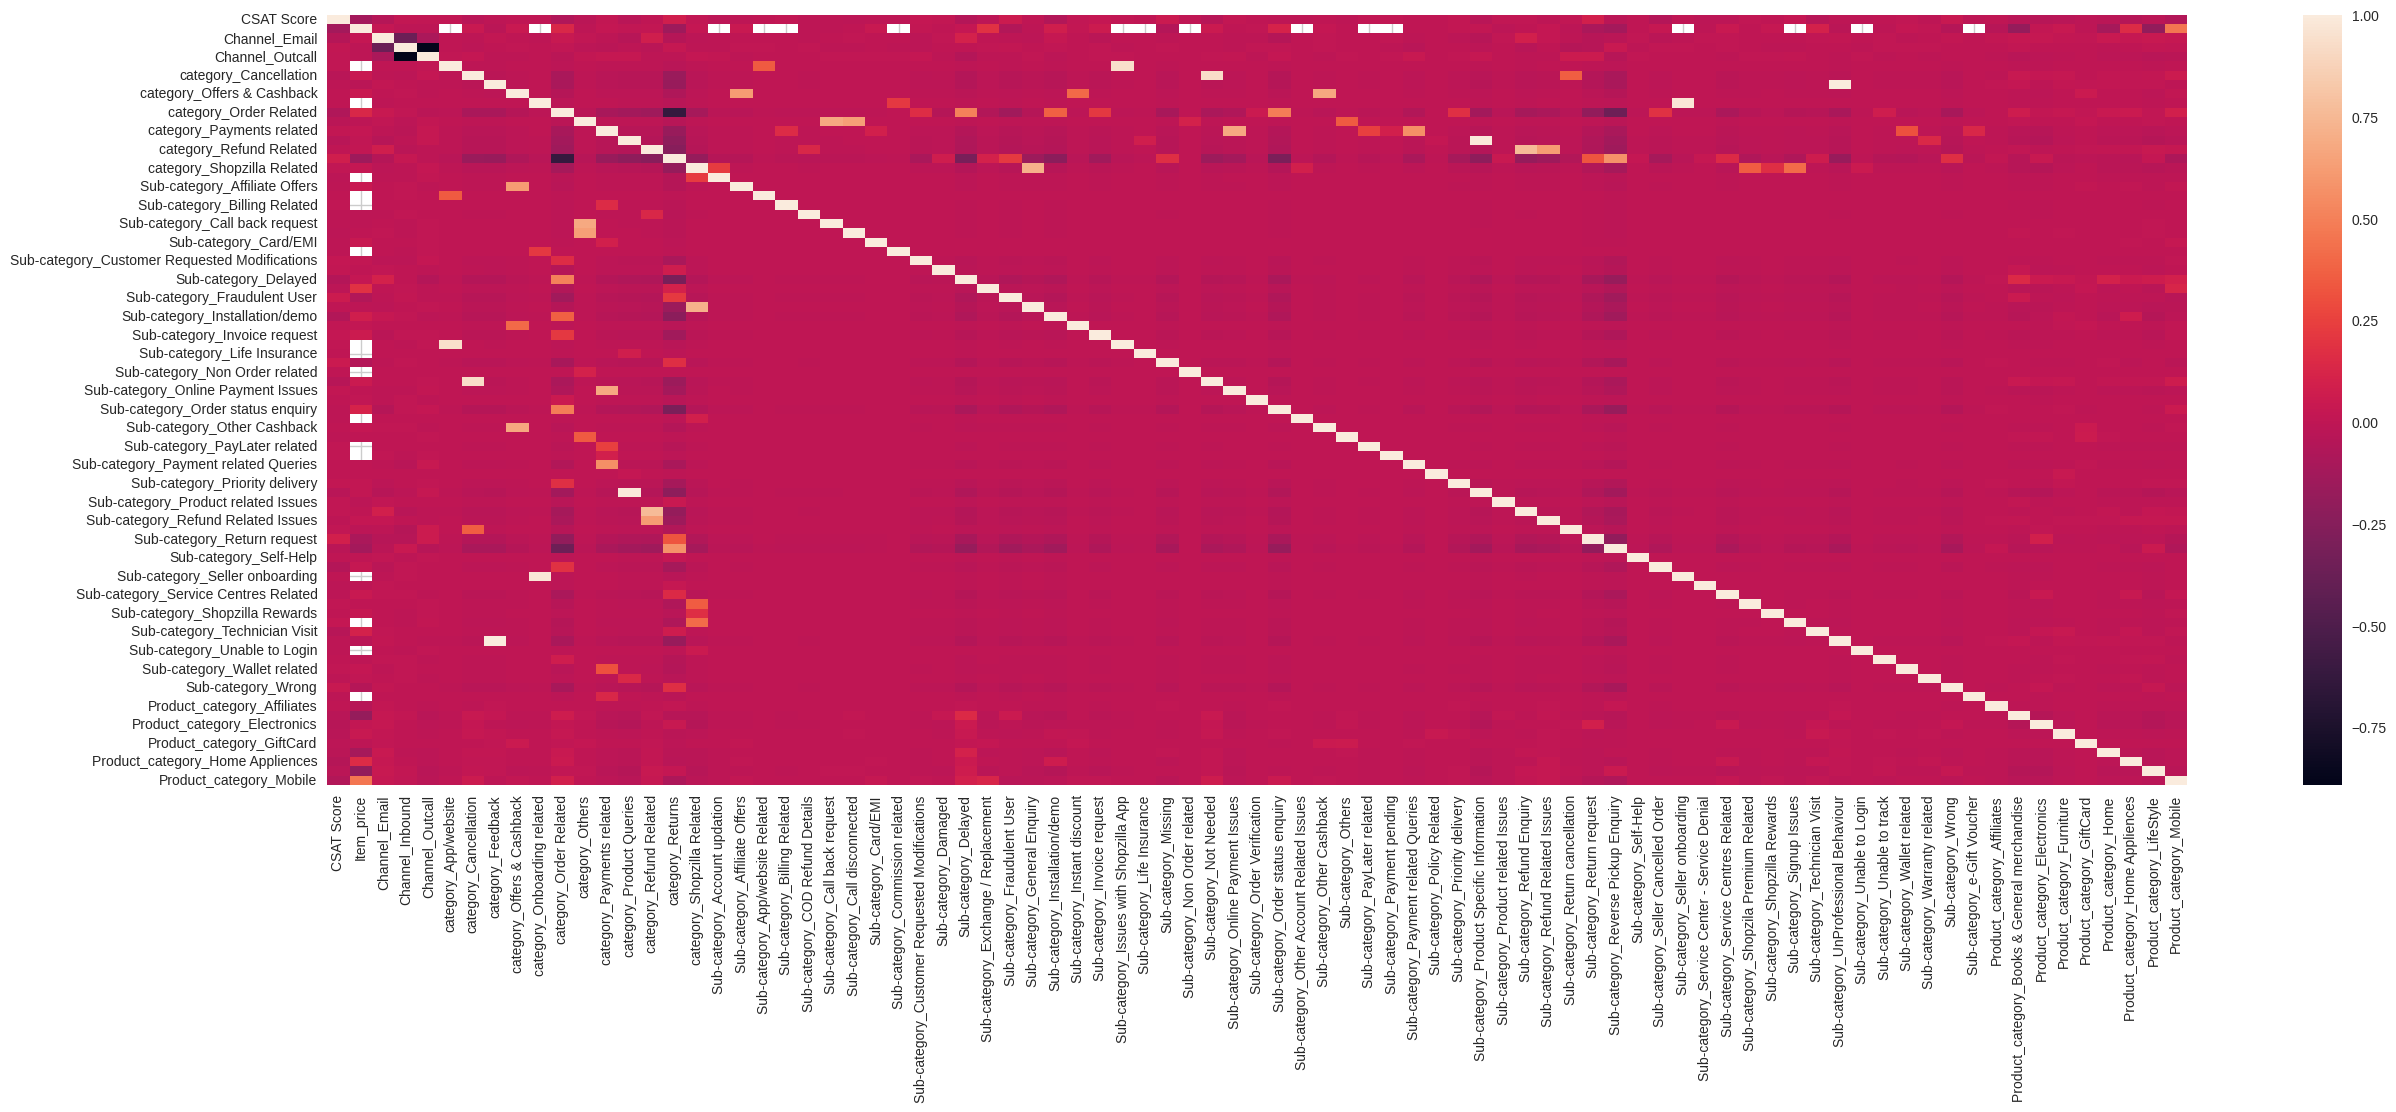

In [12]:
fig,ax = plt.subplots(figsize=(30,10))
sns.heatmap(pd.get_dummies(p1.drop(['Agent_name','Customer_City'],axis=1)).corr(),ax=ax);plt.show()

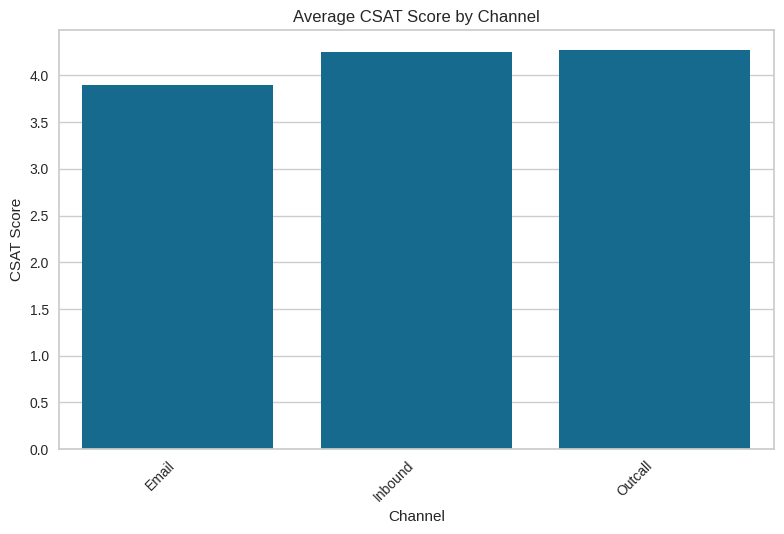

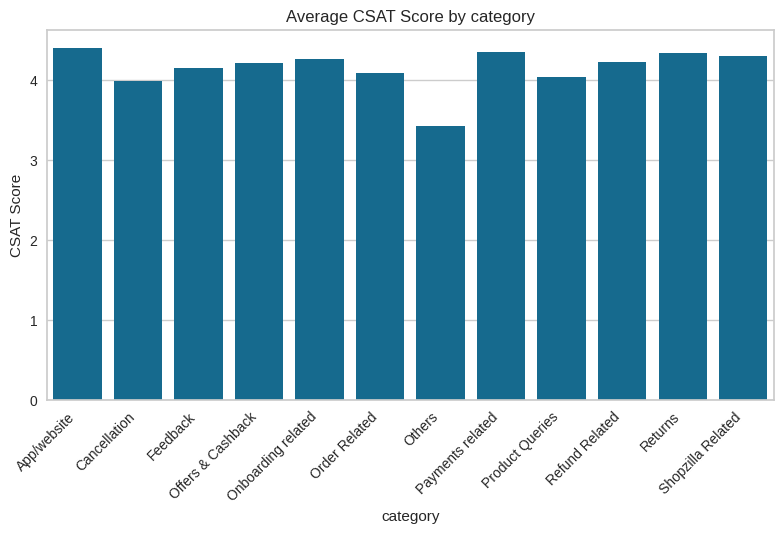

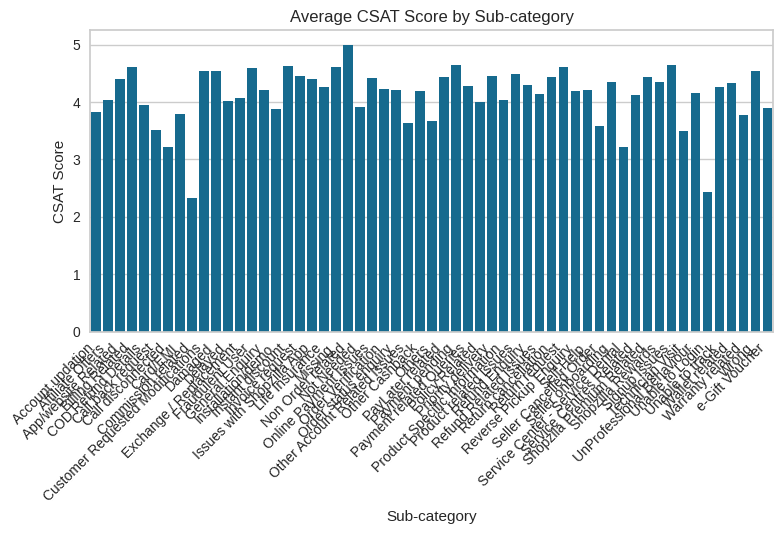

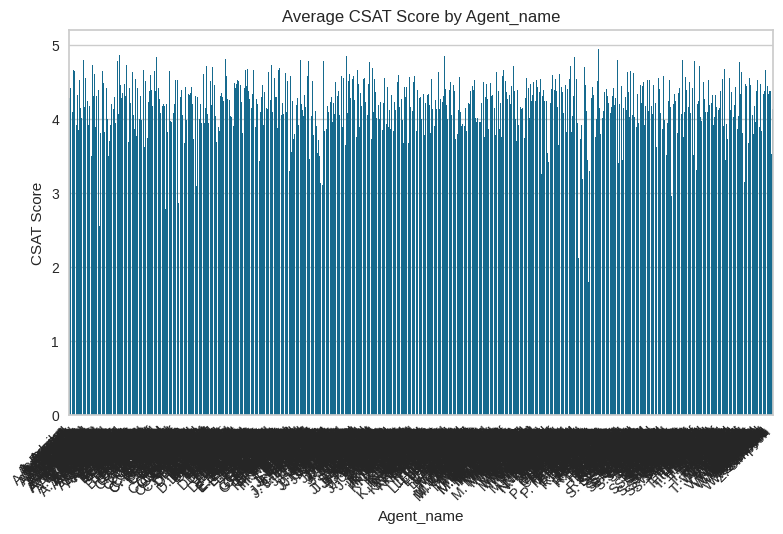

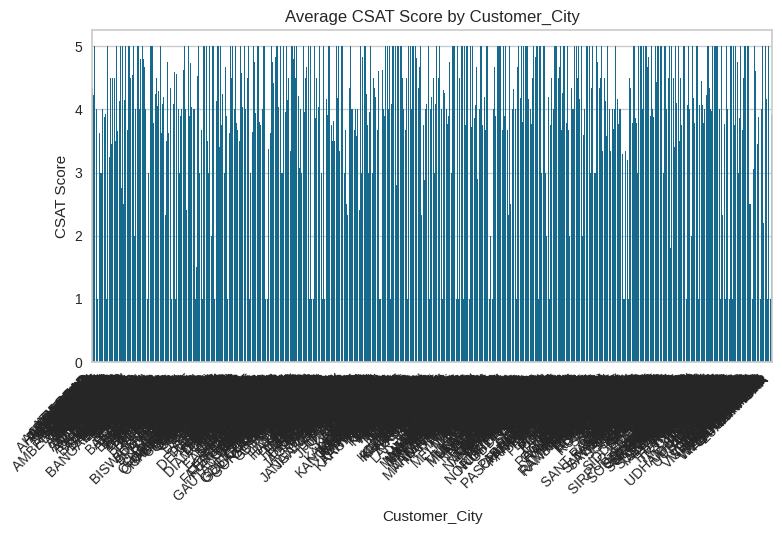

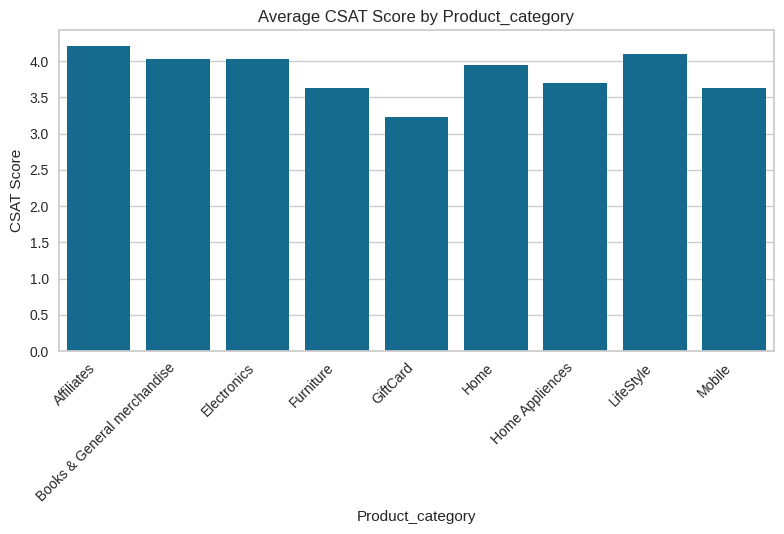

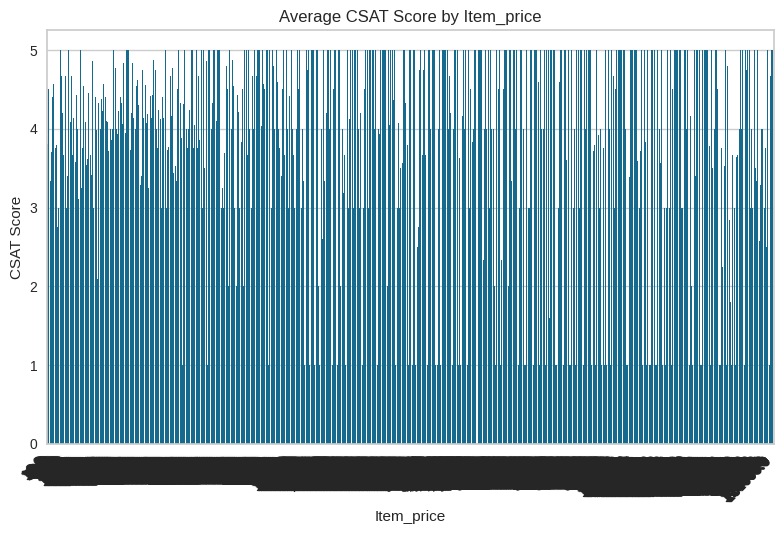

In [37]:
def plot_avg_csat(df):
  for col in df.columns:
    if col != 'CSAT Score':
      avg_csat = df.groupby(col)['CSAT Score'].mean().reset_index()
      plt.figure()  # Create a new figure for each plot
      sns.barplot(x=col, y='CSAT Score', data=avg_csat)
      plt.title(f'Average CSAT Score by {col}')
      plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for readability
      plt.tight_layout()  # Adjust layout to prevent labels from overlapping
      plt.show()
plot_avg_csat(p1)

# 2. Постройте на получившимся датасете Customer support модель дерева решений и проанализируйте важность признаков. Сделайте вывод об адекватности наших предположений.

,CSAT Score,Item_price,Channel_Email,Channel_Inbound,Channel_Outcall,category_App/website,category_Cancellation,category_Feedback,category_Offers & Cashback,category_Onboarding related,...,Sub-category_e-Gift Voucher,Product_category_Affiliates,Product_category_Books & General merchandise,Product_category_Electronics,Product_category_Furniture,Product_category_GiftCard,Product_category_Home,Product_category_Home Appliences,Product_category_LifeStyle,Product_category_Mobile
0,1,NaN,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,4,1499.0,False,True,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
2,5,NaN,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,5,NaN,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,NaN,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


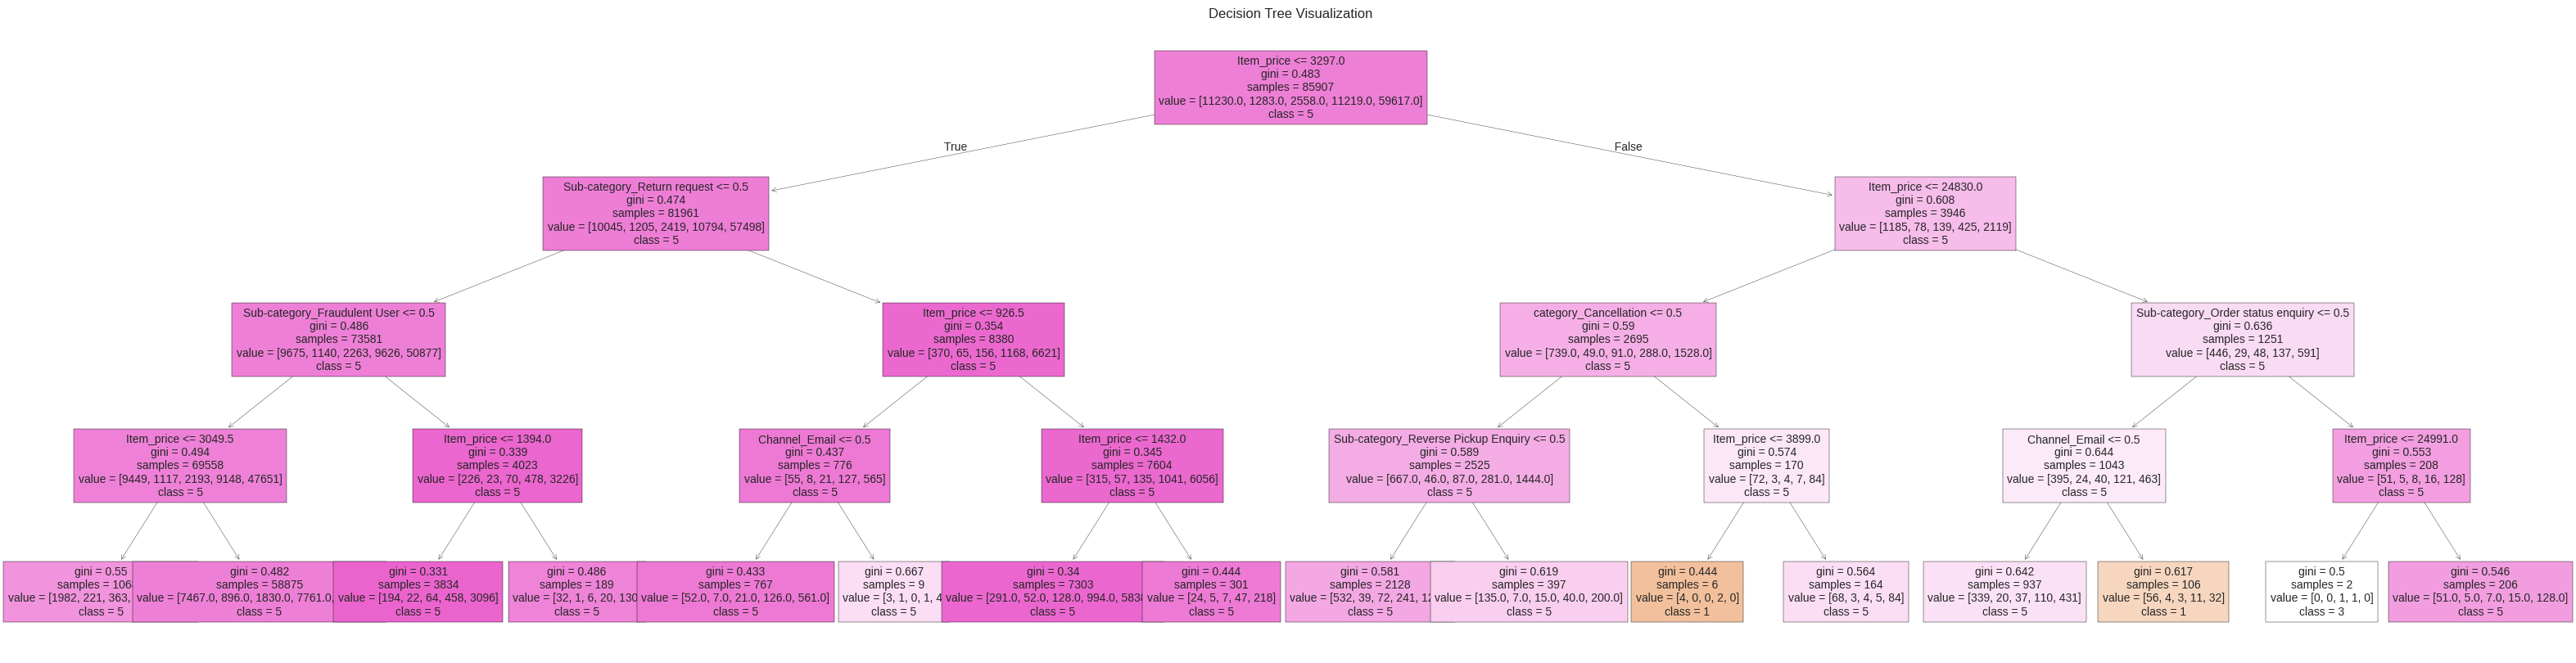

In [24]:
p2 = p1.drop(['Agent_name','Customer_City'],axis=1)
p2 = pd.get_dummies(p2)
display(p2.head())
x = p2.drop('CSAT Score',axis=1)
y = p2['CSAT Score']
m = DTC(max_depth = 4)
m.fit(x,y)
m.score(x,y)
plt.figure(figsize=(40, 10))  # Adjust figure size as needed
plot_tree(m,
          feature_names=x.columns,
          class_names=[str(c) for c in sorted(y.unique())], # Correct Class Names
          filled=True,
          fontsize=10)  # Adjust fontsize as needed
plt.title("Decision Tree Visualization")
plt.show()

# 3. Разбейте датасет на тестовую и обучающую выборки и преобразуйте обе подвыборки. Тестовую нужно преобразовывать точно также, как и обучающую (с теми же параметрами).

In [29]:
def preprocess_data(df):
  df["Customer Remarks New"] = (df["Customer Remarks"].str.len() > 3).astype(int)
  df["Is_order"] = (df["Order_id"].isna()).astype(int)
  df.loc[~df["Sub-category"].isin([
      "Reverse Pickup Enquiry", "Return request", "Delayed", "Order status enquiry",
      "Installation/demo", "Fraudulent User", "Product Specific Information"
      ]), "Sub-category"] = "Other"

  df['Agent_count'] = df.groupby(["Agent_name"])["Agent_name"].transform('count')
  df['Product_category'] = df['Product_category'].fillna('unknown')

  return df

def split_and_preprocess(p, test_size=0.2, random_state=42):
    p_train, p_test = train_test_split(p, test_size=test_size, random_state=random_state)

    p_train = preprocess_data(p_train)
    p_test = preprocess_data(p_test)

    return p_train, p_test

train,test = split_and_preprocess(p)

# 4. Проведите полный анализ на датасете Титаник, включая все необходимые визуализации и выводы.

In [33]:

T_data = pd.read_csv('titanic.csv', index_col=0)
display(T_data.head())
LE_sex = LabelEncoder()
T_data.Sex = LE_sex.fit_transform(T_data.Sex)
T_data.Pclass.replace({
    'first': 1, 'second': 2, 'third': 3
}, inplace=True)

OH_embarked = OHE(sparse_output=False)
OH_embarked.fit_transform(T_data[['Embarked']])
OH_embarked.get_feature_names_out(['Embarked'])
dummies = pd.DataFrame(OH_embarked.fit_transform(T_data[['Embarked']]),
                       columns=OH_embarked.get_feature_names_out(['Embarked']),
                       index = T_data.index)
T_dummies = pd.concat([T_data, dummies]).drop(["Embarked"], axis=1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# 5. Проверьте целесообразность каждого необязательного преобразования данных путем проверки, увеличивает ли данное преобразование точность модели. Проверьте на простом виде модели (линейная регрессия, дерево решений или случайный лес). Поэкспериментируйте с различными вариантами преобразований.

In [42]:
models = [LR(max_iter=1000), DTC(), RFC()]
model_names = ['LR', 'DTC', 'RFC']

T_data = pd.read_csv('titanic.csv', index_col=0)

# Простые функции подготовки данных
def encode_sex_le(df):
    df = df.copy()
    le = LabelEncoder()
    df['Sex'] = le.fit_transform(df['Sex'])
    return df

def encode_embarked_oh(df):
    df = df.copy()
    oh = OHE(sparse_output=False, handle_unknown='ignore')
    embarked = oh.fit_transform(df[['Embarked']])
    emb_cols = oh.get_feature_names_out(['Embarked'])
    embarked_df = pd.DataFrame(embarked, columns=emb_cols, index=df.index)
    df = pd.concat([df.drop(columns=['Embarked']), embarked_df], axis=1)
    return df

def drop_embarked(df):
    return df.drop(columns=['Embarked'])

def do_nothing(df):
    return df

# Способы работы с признаками
embarked_funcs = [encode_embarked_oh, drop_embarked]

# Выбор фичей
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']  # базовые числовые + категориальные после обработки
target = 'Survived'

best_scores = {name: [] for name in model_names}

for emb_f in embarked_funcs:
    df_ = T_data.copy()
    df_.Pclass.replace({'first': 1, 'second': 2, 'third': 3}, inplace=True)
    df_=encode_sex_le(df_)
    df_ = emb_f(df_)
    df_ = df_.dropna(subset=features + [target])

    X = df_[features]
    y = df_[target]

    for model, name in zip(models, model_names):
        score = cross_val_score(model, X, y, cv=5).mean()
        best_scores[name].append((score, emb_f.__name__))

# Сортировка результатов
for name in best_scores:
    best_scores[name].sort(reverse=True)

# Функция красивого отображения
def show_colored(top):
    for model, results in top.items():
        df = pd.DataFrame(results, columns=['Score', 'Embarked encode'])
        styled = df.style.background_gradient(
            subset=['Score'], cmap='RdYlGn', vmin=0, vmax=1
        ).set_caption(f'Top-{df.shape[0]} scores for {model}')
        display(styled)

# Вывод топ-3 для каждой модели
top3 = {name: best_scores[name][:3] for name in best_scores}
show_colored(top3)


,Score,Embarked encode
0,0.789954,encode_embarked_oh
1,0.789954,drop_embarked


,Score,Embarked encode
0,0.761982,encode_embarked_oh
1,0.760573,drop_embarked


,Score,Embarked encode
0,0.809593,drop_embarked
1,0.805417,encode_embarked_oh


# 6. Создайте воспроизводимый код обработки данного датасета.

In [43]:
T_data = pd.read_csv('titanic.csv', index_col=0)

def transform_titanic_data(df):
    df = df.copy()
    LE_sex = LabelEncoder()
    df.Sex = LE_sex.fit_transform(df.Sex)
    df.Pclass.replace({
        'first': 1, 'second': 2, 'third': 3
    }, inplace=True)

    OH_embarked = OHE(sparse_output=False, handle_unknown='ignore')
    embarked_encoded = OH_embarked.fit_transform(df[['Embarked']])
    embarked_df = pd.DataFrame(embarked_encoded,
                                columns=OH_embarked.get_feature_names_out(['Embarked']),
                                index=df.index)

    df = pd.concat([df, embarked_df], axis=1)
    df.drop(["Embarked"], axis=1, inplace=True)
    return df
transform_titanic_data(T_data)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked_C,Embarked_Q,Embarked_S,Embarked_nan
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,0.0,0.0,1.0,0.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,1.0,0.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,0.0,0.0,1.0,0.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,0.0,0.0,1.0,0.0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",1,27.0,0,0,211536,13.0000,NaN,0.0,0.0,1.0,0.0
887,888,1,1,"Graham, Miss. Margaret Edith",0,19.0,0,0,112053,30.0000,B42,0.0,0.0,1.0,0.0
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",0,NaN,1,2,W./C. 6607,23.4500,NaN,0.0,0.0,1.0,0.0
889,890,1,1,"Behr, Mr. Karl Howell",1,26.0,0,0,111369,30.0000,C148,1.0,0.0,0.0,0.0


# Доп. задания

# 1. Проведите полный анализ и преобразование категориальных атрибутов на датасете, который использовался в предыдущей работе.

##анализ

###визуализируем данные

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  35064 non-null  int64  
 1   No          35064 non-null  int64  
 2   SO2         35064 non-null  float64
 3   NO2         35064 non-null  float64
 4   CO          35064 non-null  float64
 5   O3          35064 non-null  float64
 6   PRES        35064 non-null  float64
 7   RAIN        35064 non-null  float64
 8   wd          35064 non-null  object 
 9   WSPM        35064 non-null  float64
 10  AQI Label   35064 non-null  object 
dtypes: float64(7), int64(2), object(2)
memory usage: 2.9+ MB
None
         Unnamed: 0            No           SO2           NO2            CO  \
count  35064.000000  35064.000000  35064.000000  35064.000000  35064.000000   
mean   17531.500000  17532.500000     18.058734     63.236861   1251.121692   
std    10122.249256  10122.249256     22.558126     39

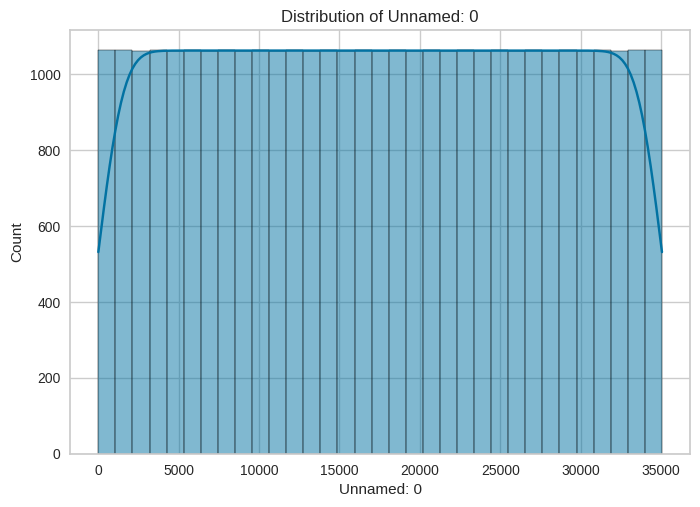

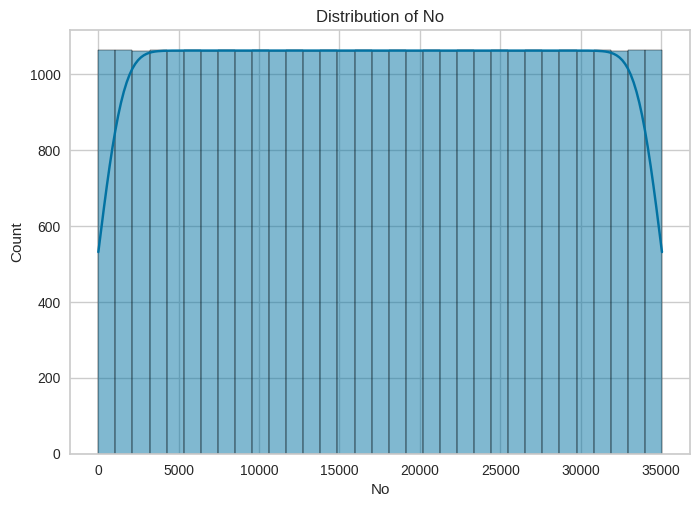

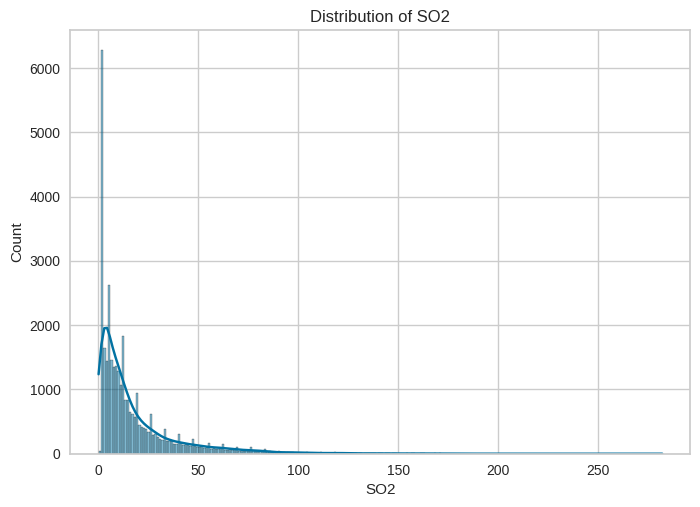

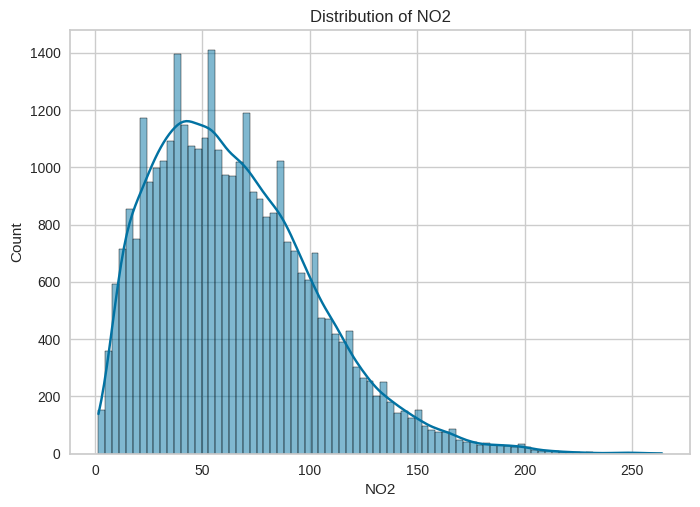

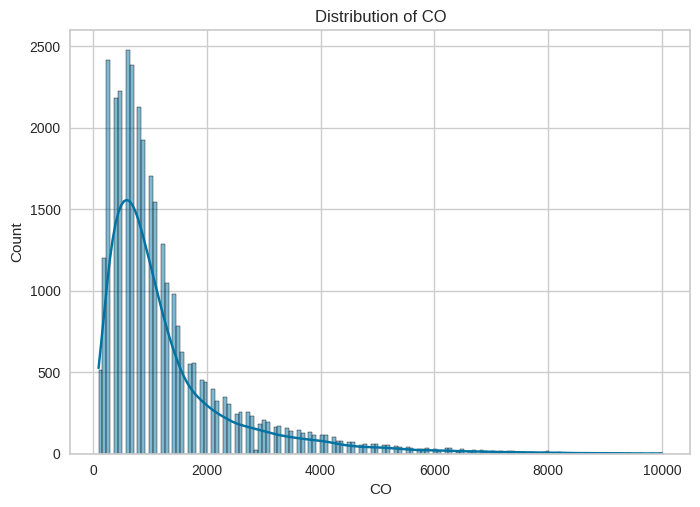

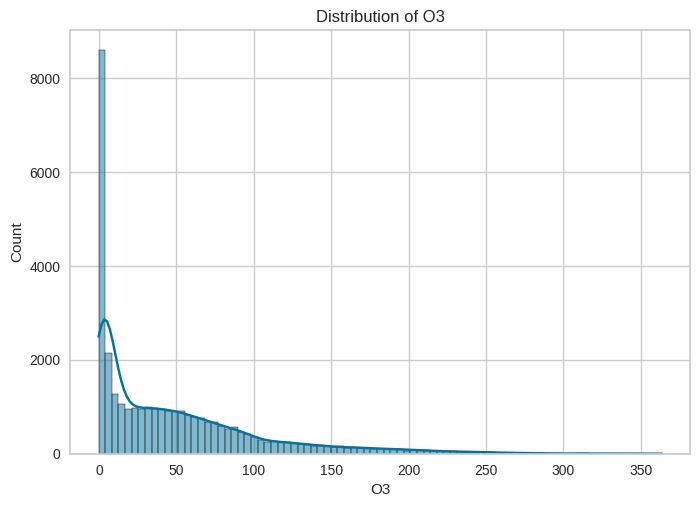

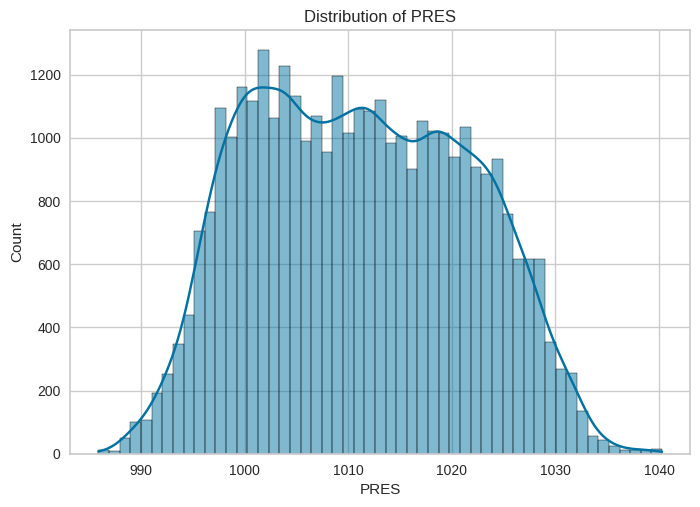

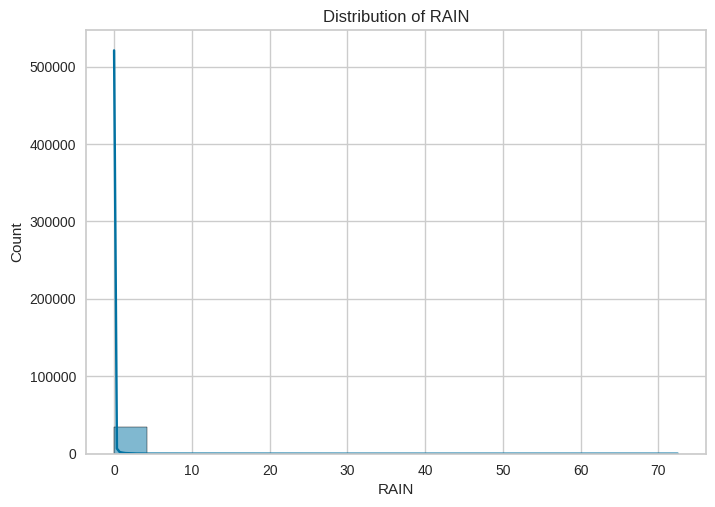

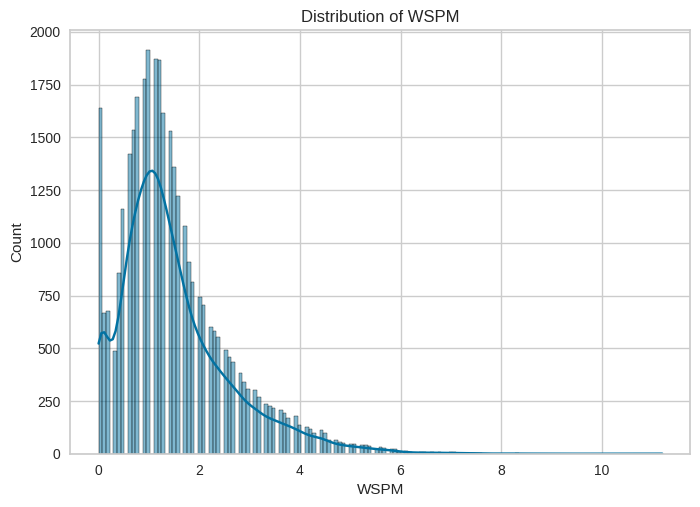

In [52]:
df = pd.read_csv("/content/PRSA_Data.csv")

print(df.info())
print(df.describe())

df = df.replace(-1, np.nan)

for col in df.select_dtypes(include=np.number):
    plt.figure()
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

### визаулизируем признаки с целевой переменной

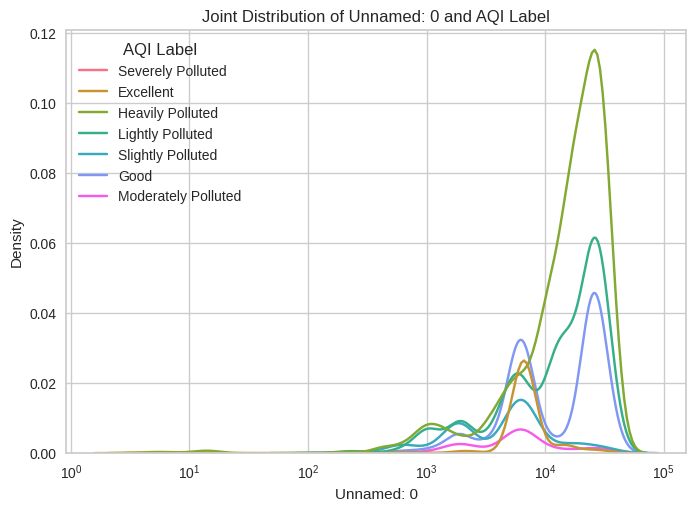

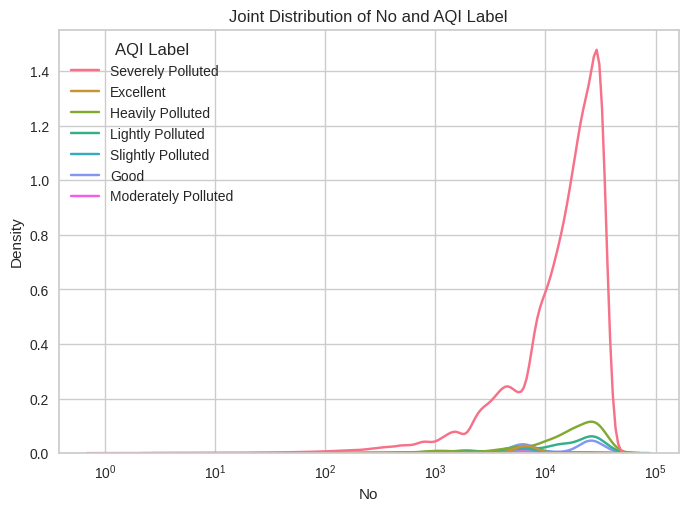

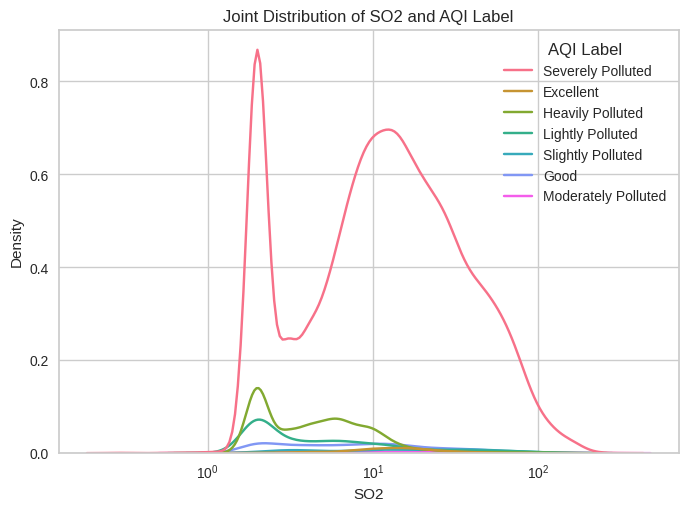

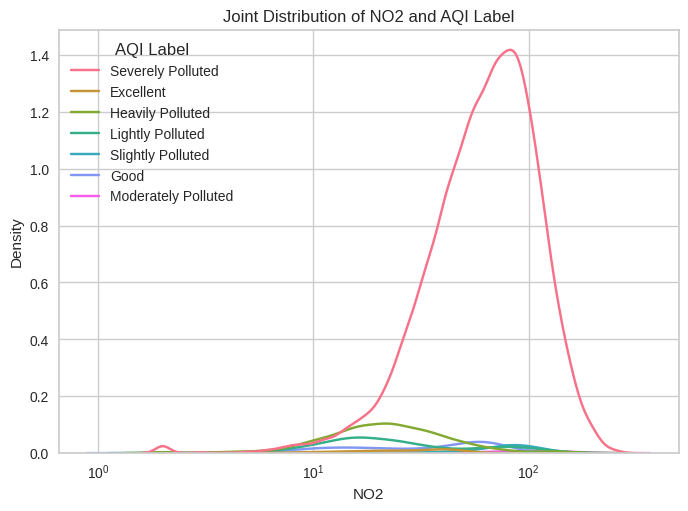

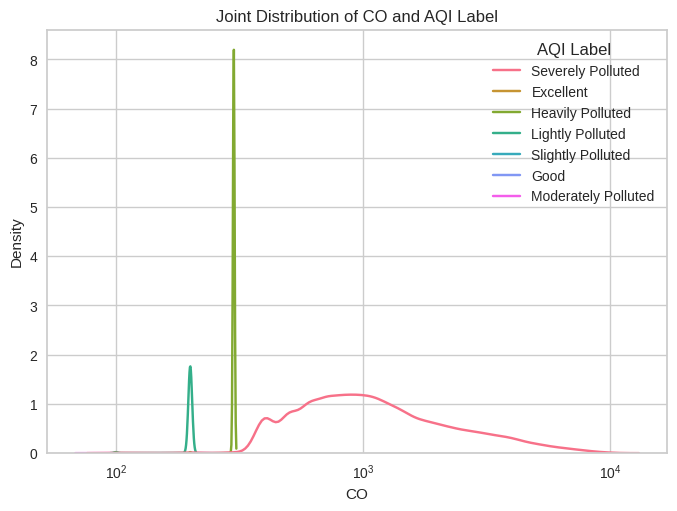

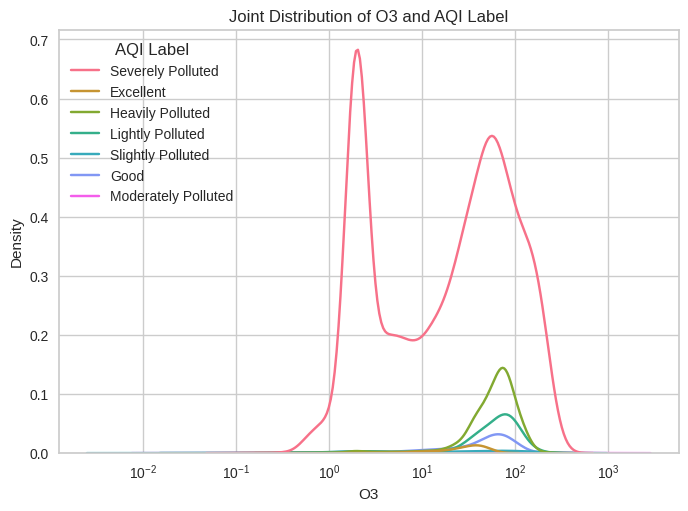

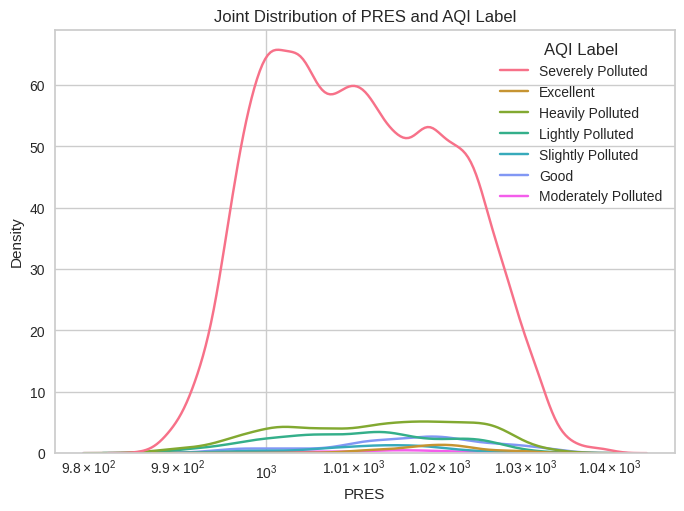

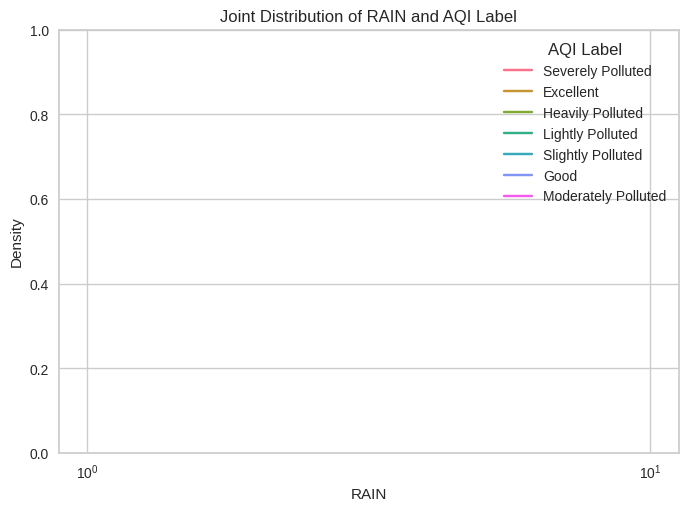

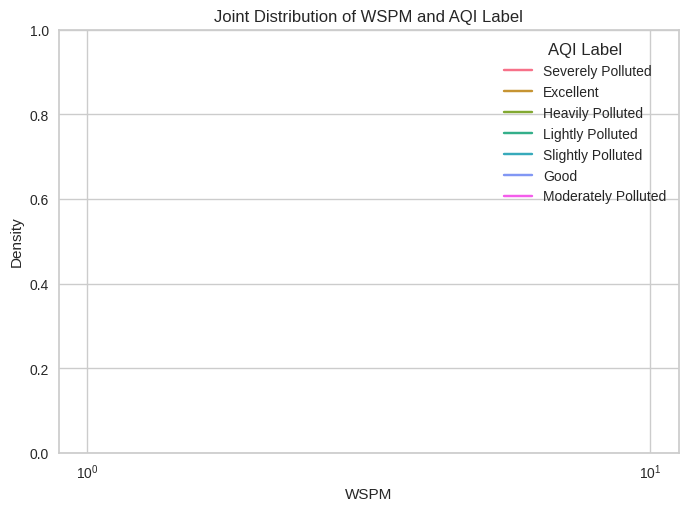

In [53]:
for col in df.select_dtypes(include=np.number):
    if col != 'AQI Label':
        plt.figure()
        try:
            sns.kdeplot(data=df, x=col, hue="AQI Label", log_scale=True)
        except:
            sns.kdeplot(data=df, x=col, hue="AQI Label")
        plt.title(f"Joint Distribution of {col} and AQI Label")
        plt.show()

### преобразуем RAIN

In [54]:
df['IS_RAIN'] = (df['RAIN'] > 0).astype(int)
df.drop(['RAIN'], axis=1, inplace=True)

### удалим выбросы и заменим Nan на медианные и случайные значения в зависимости от количества пропусков

In [55]:
#  по принципу RQ
def clip_outliers(df, col, lower_percentile=0.05, upper_percentile=0.95):
    lower_bound = df[col].quantile(lower_percentile)
    upper_bound = df[col].quantile(upper_percentile)
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
    return df

for col in df.select_dtypes(include=np.number):
    df = clip_outliers(df, col)

# если пропусков больше 5% заменим на рандомные значения из присутствующих, иначе на медианные
for col in df.select_dtypes(include=np.number):
    if df[col].isnull().any():
        if df[col].isnull().sum() / len(df) < 0.05:
            df[col] = df[col].fillna(df[col].median())
        else:
            filler = df[col][df[col].isna()]
            sampled_values = df[col][~df[col].isna()].sample(n=len(filler), replace=True).set_axis(filler.index)
            df[col] = df[col].fillna(sampled_values)


### избавимся от лишней точности O3 (в отличие от остальных столбцов (5 знаков) у него 7 знаков после запятой)

In [56]:
df['O3'] = np.round(df['O3']).astype(int)

###  прологарифмируем

In [57]:
for col in df.select_dtypes(include=np.number):
    if col not in ['IS_RAIN']:
        df[col] = np.log1p(df[col])

# 2. (*) Создайте код, реализующий алгоритм очистки данных автоматически (для любого датасета).

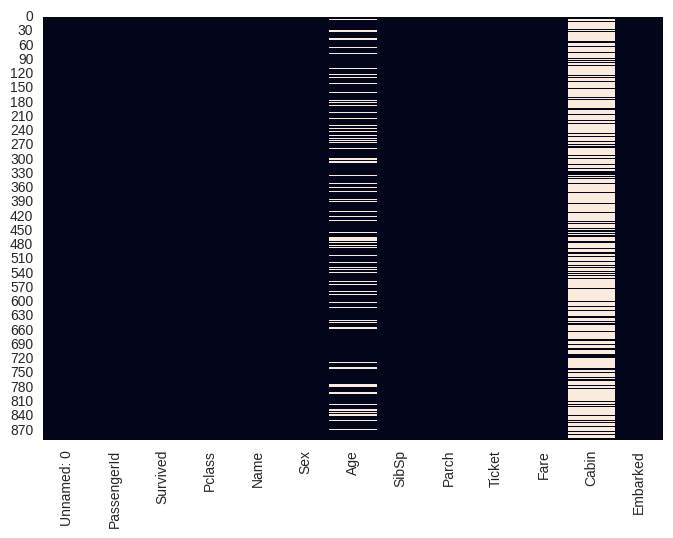

(891, 13)

<class 'pandas.core.frame.DataFrame'>
Index: 561 entries, 87 to 805
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   561 non-null    int64  
 1   PassengerId  561 non-null    int64  
 2   Survived     561 non-null    int64  
 3   Pclass       561 non-null    object 
 4   Name         561 non-null    object 
 5   Sex          561 non-null    object 
 6   Age          561 non-null    float64
 7   SibSp        561 non-null    int64  
 8   Parch        561 non-null    int64  
 9   Ticket       561 non-null    object 
 10  Fare         561 non-null    float64
 11  Embarked     561 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 57.0+ KB


None

,Unnamed: 0,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
87,87,88,0,third,"Slocovski, Mr. Selman Francis",male,28.0,0,0,SOTON/OQ 392086,8.0500,S
89,89,90,0,third,"Celotti, Mr. Francesco",male,24.0,0,0,343275,8.0500,S
90,90,91,0,third,"Christmann, Mr. Emil",male,29.0,0,0,343276,8.0500,S
91,91,92,0,third,"Andreasson, Mr. Paul Edvin",male,20.0,0,0,347466,7.8542,S
92,92,93,0,first,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.1750,S
...,...,...,...,...,...,...,...,...,...,...,...,...
799,799,800,0,third,"Van Impe, Mrs. Jean Baptiste (Rosalie Paula Go...",female,30.0,1,1,345773,24.1500,S
800,800,801,0,second,"Ponesell, Mr. Martin",male,34.0,0,0,250647,13.0000,S
801,801,802,1,second,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",female,31.0,1,1,C.A. 31921,26.2500,S
802,802,803,1,first,"Carter, Master. William Thornton II",male,11.0,1,2,113760,120.0000,S


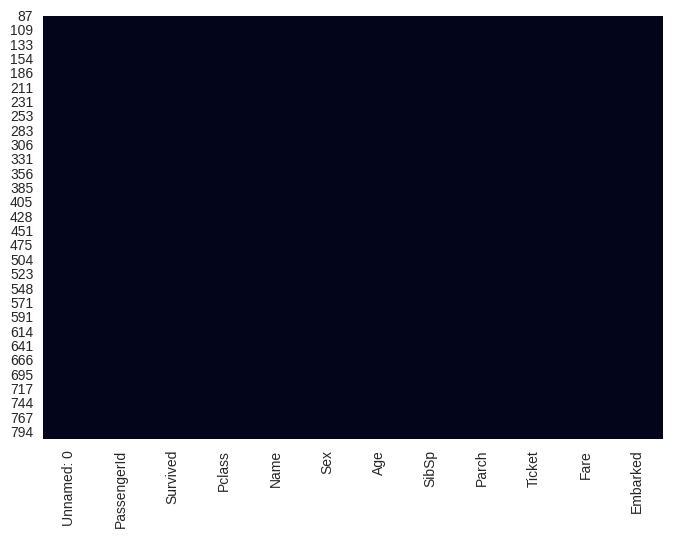

(561, 12)

In [45]:
def auto_clean(df, quant = 0.75, drop_half = True):
    if drop_half:
      # просто дропнем все признаки которые в которых нет и половины заполненных строк
      df = df.dropna(axis=1, thresh=0.5 * len(df))
    num_cols = df.select_dtypes(include=['int64', 'float64']).columns
    cat_cols = df.select_dtypes(include=['object']).columns

    # численные заменяем медианой потому что она устойчива к выбросам
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    # категориальные заменяем модой потому что для них сами значения не имеют смысла, а важно их количество
    df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

    # дубликаты убираем
    df.drop_duplicates(inplace=True)

    for col in num_cols:
        lower_bound = df[col].quantile(1 - quant)
        upper_bound = df[col].quantile(quant)
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    return df


sns.heatmap(pd.read_csv('/content/titanic.csv').isna(), cbar=False);plt.show()
display(pd.read_csv('/content/titanic.csv').shape)
cleaned_titanic = auto_clean(pd.read_csv('/content/titanic.csv'), 0.95)
display(cleaned_titanic.info())
display(cleaned_titanic)
sns.heatmap(cleaned_titanic.isna(), cbar=False);plt.show()
display(cleaned_titanic.shape)